# 시간창을 검증 데이터로 선택한 이상 탐지 비교

Isolation Forest와 MiniBatch K-means의 통합 / Adapter별 / 통합+Adapter 앙상블 6개를 비교한다. **시간창은 별도 검증 데이터에서 선택하고, 선택을 고정한 뒤 모델을 다시 학습해 원래 평가셋에 적용**했다.

시간창 길이 W분과 판단 주기 1분은 다르다. 예를 들어 W=5이면 10:05에 10:00~10:05를 보고, 10:06에는 10:01~10:06을 본다. 개별 Process 행 평가와 시간창 평가는 분리한다. 노트북 실행은 이미 저장된 결과를 읽을 뿐 재학습하거나 test F1로 임계값을 조정하지 않는다.

> 공개 저장소용 연구 스냅샷입니다. 원본·평가 데이터셋과 학습/검증 캐시, 행별 예측 배열은 포함하지 않습니다. 개별 원본 로그 미리보기 출력은 제거했습니다. 집계 표와 그림은 저장된 실험 결과이며, 원본 기반 분석을 재실행하려면 별도 데이터가 필요합니다.

In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'code/model_evaluation/evaluate.py').is_file())
sys.path.insert(0, str(ROOT / 'code'))
from model_evaluation import plots
from model_evaluation.models import METHODS

RESULTS = ROOT / 'reports/model_evaluation_v2'
if not (RESULTS / 'summary.json').is_file():
    raise FileNotFoundError('먼저 code/model_evaluation/evaluate.py를 실행하세요.')
summary = json.loads((RESULTS / 'summary.json').read_text(encoding='utf-8'))
plots.style()

def show(fig):
    display(fig)
    plt.close(fig)

def formatted(frame):
    formats = {c:'{:.2%}' for c in ['Accuracy','Precision','Recall','F1','정상 오탐률','모두 정상 예측 Accuracy'] if c in frame}
    formats.update({c:'{:,.0f}' for c in ['평가 수','정상 수','이상 수'] if c in frame})
    return frame.style.format(formats, na_rep='N/A').hide(axis='index')

case_count = sum(d['cases'] for d in summary['datasets'])
full = summary['protocol']['identity']['max_cases'] is None
display(Markdown(f'**실행 범위: {"전체 평가" if full else "개발용 표본 평가"}. 이상 사례 {case_count:,}개 + 정상 대조 사례 {case_count:,}개.**'))
if full:
    assert case_count == 31000

BASELINE = ROOT / 'reports/model_evaluation_v2_baseline_1m'
baseline = json.loads((BASELINE / 'summary.json').read_text(encoding='utf-8'))
selection = summary['protocol']['window_selection']
width = summary['protocol']['window_minutes']
assert summary['pooled']['window'][0]['n'] == baseline['pooled']['window'][0]['n']
assert summary['pooled']['window'][0]['anomaly'] == baseline['pooled']['window'][0]['anomaly']
display(Markdown(f'**검증 선택: 최근 {width}분을 집계, 1분마다 판단.** 원본 평가셋·정답·판단 시점은 고정.'))

**실행 범위: 전체 평가. 이상 사례 31,000개 + 정상 대조 사례 31,000개.**

**검증 선택: 최근 5분을 집계, 1분마다 판단.** 원본 평가셋·정답·판단 시점은 고정.

In [2]:
plt.rcParams['font.family'] = [plt.rcParams['font.family'][0], 'DejaVu Sans']

## 0. 왜 이 시간창을 선택했나?

후보는 1·2·3·5·10·15분이다. 기초 과거 이력이 1분 해상도라 30초는 제외했다. 모든 후보는 동일한 1분 판단·정답 격자에서 평가한다. 검증용 기본 6개 시나리오마다 새 사례 240개와 짝 정상 대조군 240개를 사용했다.

선택 기준은 **시나리오별 F1을 같은 비중으로 평균하고, 6개 모델도 같은 비중으로 평균**한 값이다. 같은 값이면 정상 오탐률이 낮은 후보, 다시 같으면 짧은 후보를 고른다. Hard 및 최종 평가 라벨·점수는 선택에 사용하지 않는다. 최종 평가는 이미 v1에서 본 적이 있는 반합성 데이터이므로 새 블라인드 외부 테스트라고 주장하지 않는다.

한 알고리즘에만 유리한 시간창이 아닌 공통 비교용 시간창을 고른다. 모델별 권장 후보가 다를 수 있고, 이는 아래 별도 표로 확인한다.

**선택의 절충:** 검증 평균 F1은 1분 10.24% → 5분 16.69%로 늘었지만 평균 정상 오탐률도 1.47% → 8.93%로 늘었다. 오탐률 상한을 제한한 최적화는 아니다. 운영에서 허용 가능한 오탐 예산을 먼저 정하면 선택이 달라질 수 있다. 또한 IF 통합은 15분, IF Adapter/앙상블은 5분, K-means 세 전략은 2분을 선호했다. 공통 5분이 모든 모델의 최적값이라는 뜻이 아니다.

시간창(분),검증 평균 F1,검증 평균 정상 오탐률,선택
1,10.24%,1.47%,False
2,15.63%,7.88%,False
3,16.07%,11.41%,False
5,16.69%,8.93%,True
10,15.99%,12.52%,False
15,15.40%,15.05%,False


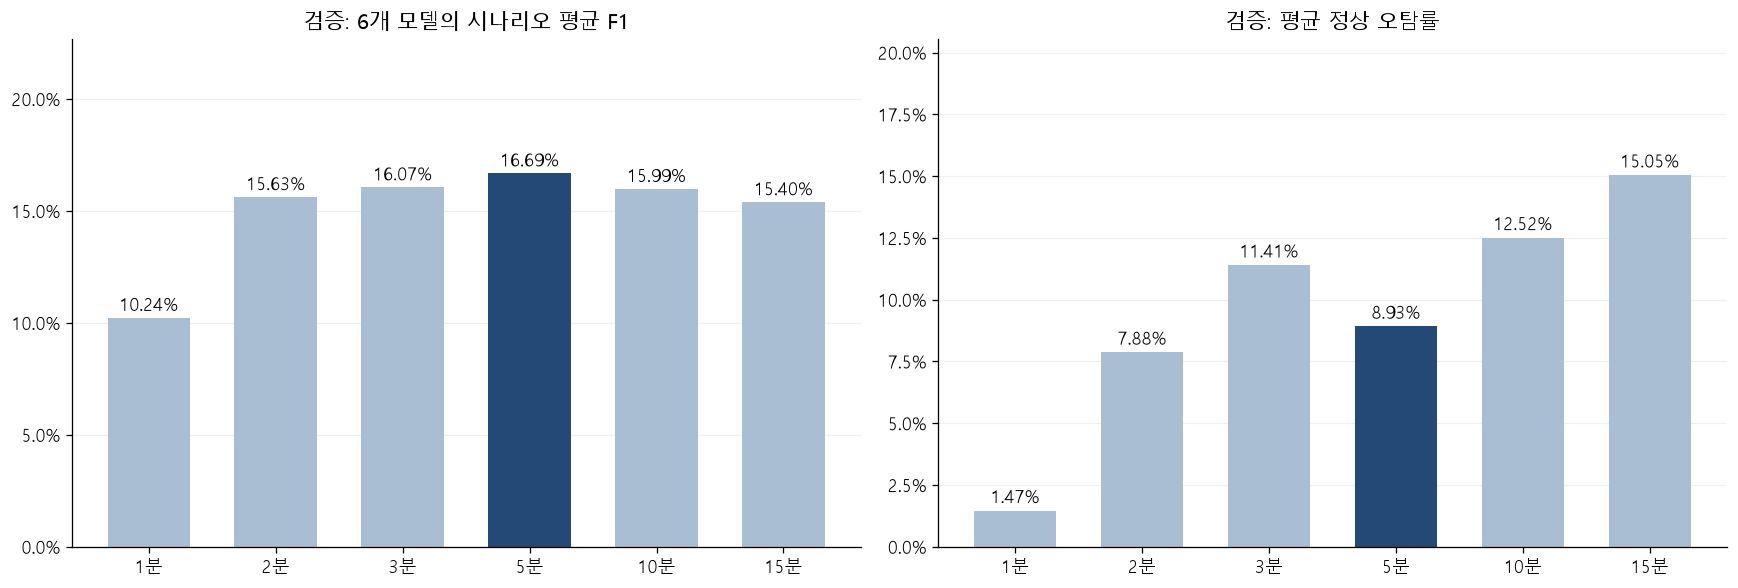

,모델,모델별 검증 최선 시간창(분)
0,IF 통합,15
1,IF Adapter,5
2,IF 앙상블,5
3,K-means 통합,2
4,K-means Adapter,2
5,K-means 앙상블,2


검증 사례 **1,440개 + 정상 대조군 1,440개**, 원본 예약 실행 **3,344개**. 시간창 정상 참조와 예약 원본의 중복은 **0개**.

시간창(분),IF 통합,IF Adapter,IF 앙상블,K-means 통합,K-means Adapter,K-means 앙상블
1,6.03%,9.59%,7.37%,10.58%,14.03%,13.82%
2,15.16%,19.57%,17.55%,11.86%,14.84%,14.80%
3,17.81%,19.67%,19.27%,11.47%,14.04%,14.13%
5,18.26%,22.28%,20.86%,11.08%,13.66%,14.00%
10,17.27%,19.86%,20.07%,11.26%,13.39%,14.11%
15,18.87%,20.29%,20.27%,9.35%,11.72%,11.91%


In [3]:
candidate_rows = [{'시간창(분)':c['minutes'], '검증 평균 F1':c['objective_macro_f1'], '검증 평균 정상 오탐률':c['mean_macro_normal_fpr'], '선택':c['minutes']==width} for c in selection['candidates']]
display(pd.DataFrame(candidate_rows).style.format({'검증 평균 F1':'{:.2%}','검증 평균 정상 오탐률':'{:.2%}'}).hide(axis='index'))
show(plots.window_search(selection))
display(pd.DataFrame([{'모델':plots.NAMES[m], '모델별 검증 최선 시간창(분)':v} for m,v in selection['per_method_best_minutes'].items()]))
display(Markdown(f"검증 사례 **{selection['validation_cases']:,}개 + 정상 대조군 {selection['validation_cases']:,}개**, 원본 예약 실행 **{selection['validation_source_templates']:,}개**. 시간창 정상 참조와 예약 원본의 중복은 **{selection['validation_source_overlaps_window_reference']}개**."))
validation_matrix = pd.DataFrame([{'시간창(분)':c['minutes'], **{plots.NAMES[r['method']]:r['f1'] for r in c['macro']}} for c in selection['candidates']])
display(validation_matrix.style.format({plots.NAMES[m]:'{:.2%}' for m in METHODS}).hide(axis='index'))

### 시간창만 바꿨을 때 최종 성능은 어떻게 달라졌나?

기존 v1과 직접 비교하면 검증용 원본 예약과 과거 요청량 계산 변경까지 섞인다. 아래는 **동일한 새 정상 참조·같은 피처 정의·같은 정답·같은 판단 시점**으로 다시 학습한 고정 1분 모델과 선택 W분 모델의 비교다. 선택 결과를 먼저 고정한 다음 두 평가를 실행했다. F1 변화만 아니라 정상 오탐률과 미탐도 함께 본다.

긴 시간창에서 장애가 끝난 뒤에도 과거 이상 값이 남아 경보가 이어질 수 있다. 이 구간은 정상 정답 그대로이므로 FP로 집계한다. 짧은 개별 이상은 긴 구간에 희석될 수도 있다. 어떤 모델이든 반드시 개선된다고 가정하지 않는다.

모델,고정 1분 F1,선택 시간창 F1,F1 변화(%p),고정 1분 Recall,선택 시간창 Recall,고정 1분 정상 오탐률,선택 시간창 정상 오탐률
IF 통합,0.047818,0.220122,+17.23,0.025138,0.142245,0.005233,0.029910
IF Adapter,0.070757,0.192899,+12.21,0.039100,0.121675,0.013165,0.027858
IF 앙상블,0.062245,0.225374,+16.31,0.033254,0.147883,0.007016,0.032753
K-means 통합,0.114094,0.149548,+3.55,0.062958,0.094845,0.008098,0.034573
K-means Adapter,0.145174,0.175202,+3.00,0.085311,0.117684,0.017920,0.044959
K-means 앙상블,0.142954,0.174422,+3.15,0.083747,0.116112,0.017511,0.042878


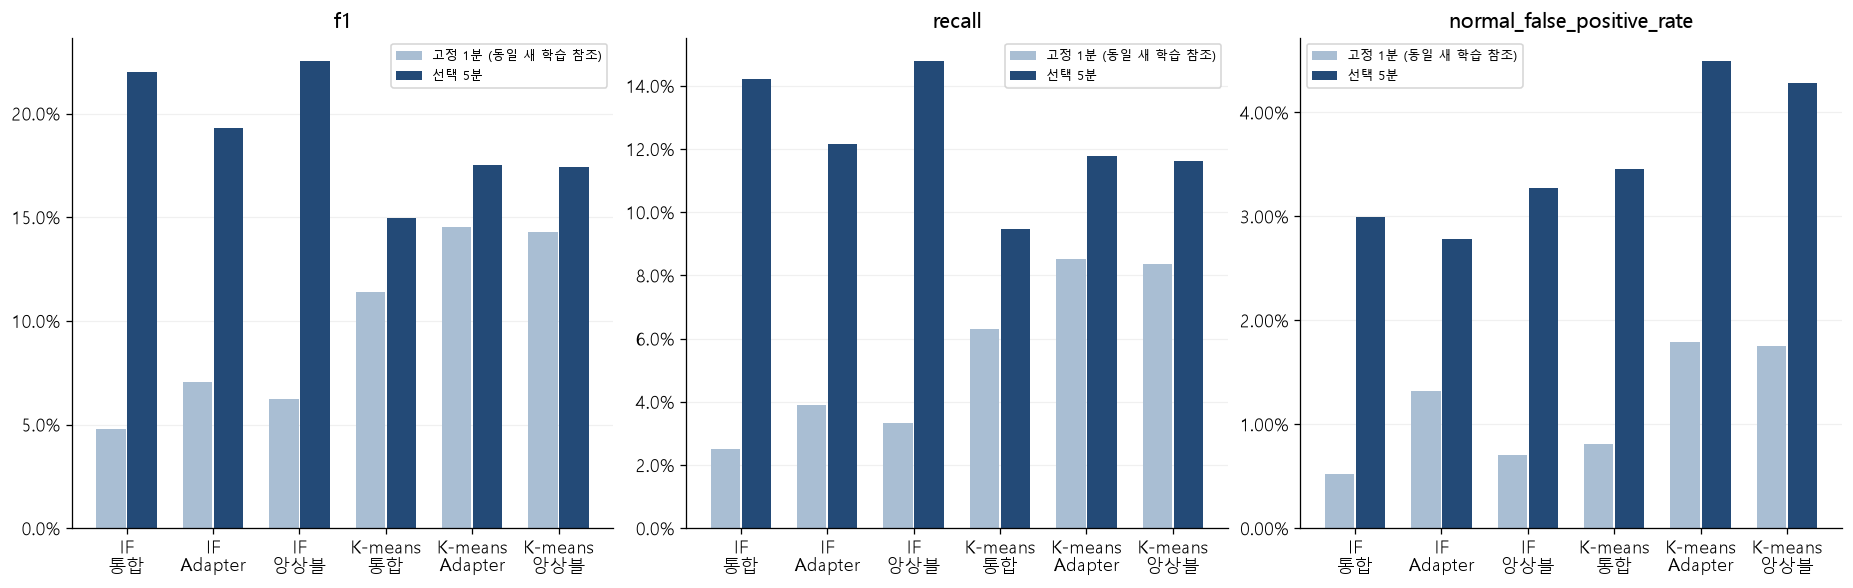

In [4]:
comparison = []
for before, after in zip(baseline['pooled']['window'], summary['pooled']['window']):
    comparison.append({'모델':plots.NAMES[after['method']], '고정 1분 F1':before['f1'], '선택 시간창 F1':after['f1'], 'F1 변화(%p)':100*(after['f1']-before['f1']), '고정 1분 Recall':before['recall'], '선택 시간창 Recall':after['recall'], '고정 1분 정상 오탐률':before['normal_false_positive_rate'], '선택 시간창 정상 오탐률':after['normal_false_positive_rate']})
display(pd.DataFrame(comparison).style.format({c:'{:.2%}' for c in comparison[0] if c not in ('모델','F1 변화(%p)')}).format({'F1 변화(%p)':'{:+.2f}'}).hide(axis='index'))
show(plots.window_before_after(baseline,summary))

### 시간창을 늘리면 입력이 무엇이 달라지나?

최근 W분의 실행 수와 완료 처리시간 P50·P95가 바뀐다. 과거 기준도 14일 합성 정상 이력의 rolling W분 실행 수에서 같은 시간대·평일/주말로 계산한다. 1분별 P95의 합이나 평균을 W분 P95로 사용하는 것이 아니다. 별도의 최근 5분 요청량은 모든 후보에서 그대로 유지한다.

사례 시작 직후에는 W분 이력이 부족하다. 미래 값을 채우거나 다른 사례와 이어 붙이지 않고 확보된 길이만 사용하며, 과거 비교 기준도 같은 길이로 맞춘다. 원본에 0건 구간이 있어도 분 단위 입력을 유지한다.

## 1. 최종 결과: 검증에서 선택한 최근 W분 시간창

6개 기본 시나리오와 혼합 Hard를 모두 포함한다. 정답과 평가 시점은 원래의 1분 격자로 유지한다. 시간창이 길어졌다고 정상 구간을 이상 라벨로 확장하지 않는다. 정상 대조군과 장애 사례의 정상 배경 구간도 평가에 포함한다.

Adapter 전략은 지원되는 Adapter만 전용 모델을 사용하고 미지원이면 통합으로 fallback한다. 앙상블은 같은 알고리즘의 통합·Adapter 점수를 50:50으로 합친다. IF와 K-means를 섞은 앙상블이 아니다.

In [5]:
display(formatted(plots.table(summary, 'window')))

모델,평가 수,정상 수,이상 수,Accuracy,Precision,Recall,F1,정상 오탐률,모두 정상 예측 Accuracy
IF 통합,"2,167,766","1,807,717","360,049",83.26%,48.64%,14.22%,22.01%,2.99%,83.39%
IF Adapter,"2,167,766","1,807,717","360,049",83.09%,46.52%,12.17%,19.29%,2.79%,83.39%
IF 앙상블,"2,167,766","1,807,717","360,049",83.12%,47.35%,14.79%,22.54%,3.28%,83.39%
K-means 통합,"2,167,766","1,807,717","360,049",82.08%,35.33%,9.48%,14.95%,3.46%,83.39%
K-means Adapter,"2,167,766","1,807,717","360,049",81.60%,34.27%,11.77%,17.52%,4.50%,83.39%
K-means 앙상블,"2,167,766","1,807,717","360,049",81.74%,35.04%,11.61%,17.44%,4.29%,83.39%


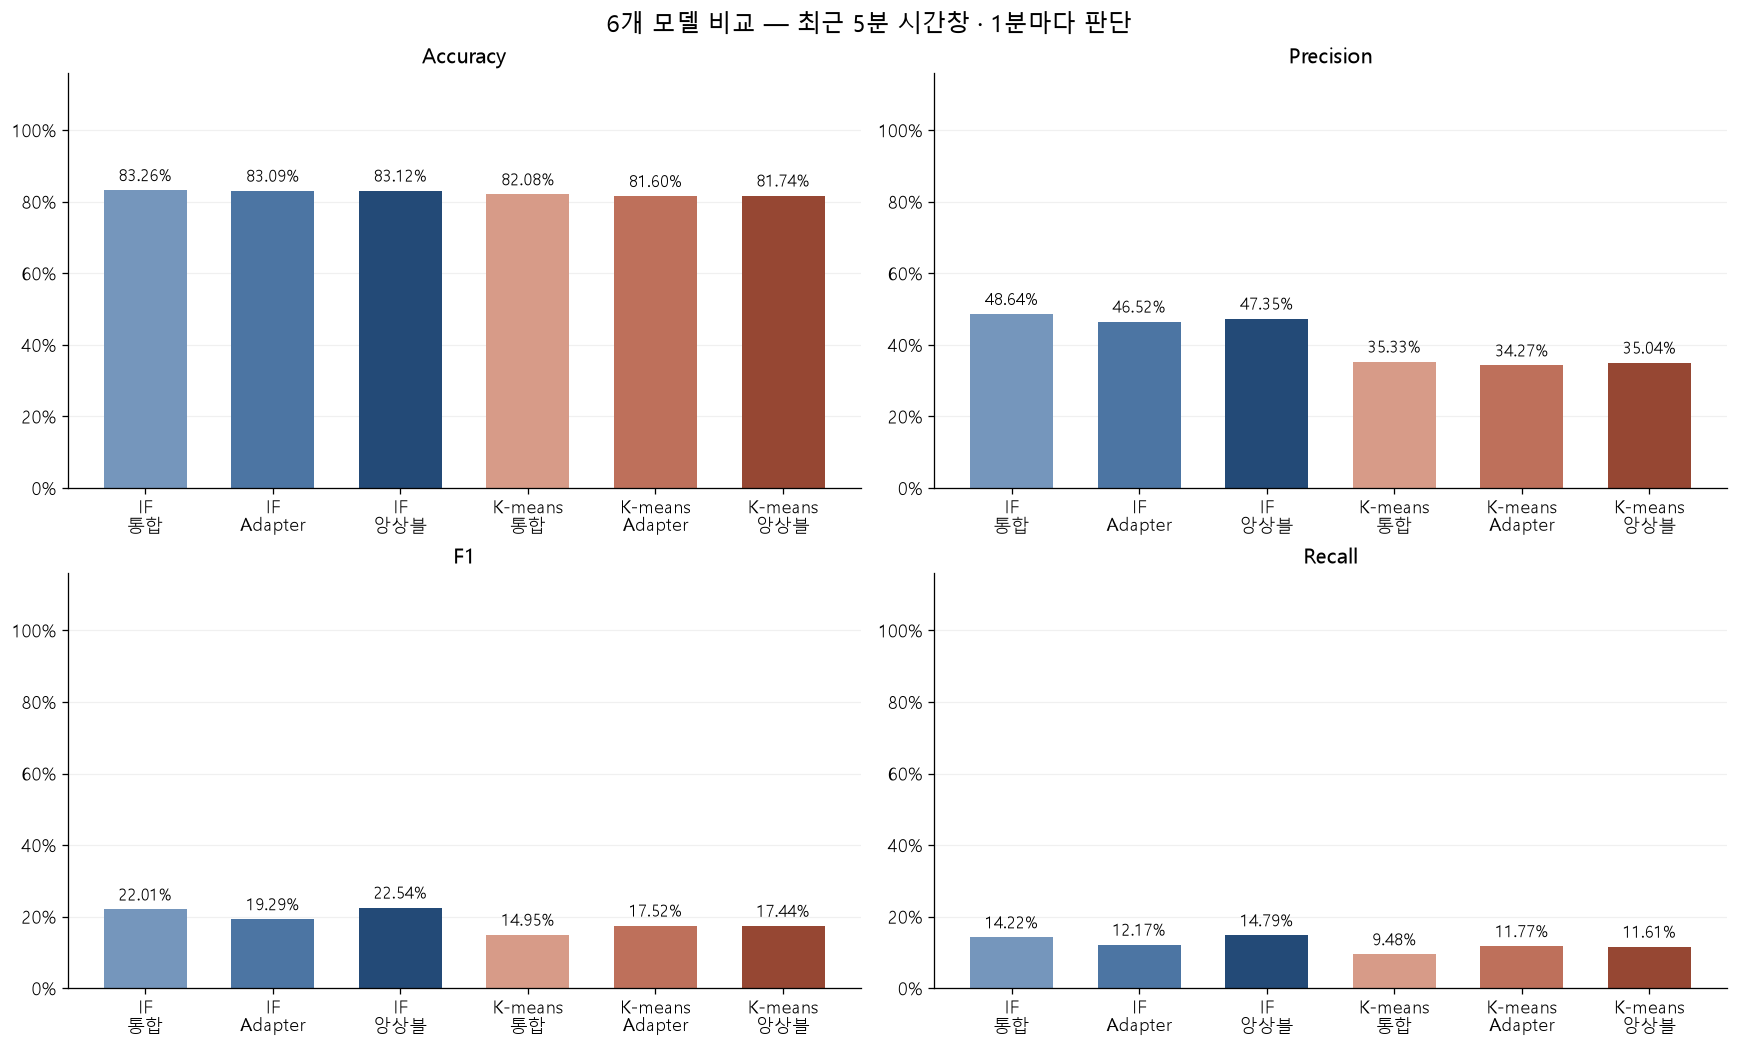

In [6]:
show(plots.overview(summary, 'window'))

### 지표 읽는 방법

- **Accuracy**: 전체 중 맞힌 비율. 정상 시간창이 많으면 이상을 놓쳐도 높을 수 있다. 표의 ‘모두 정상 예측 Accuracy’와 비교한다.
- **Precision**: 이상이라고 알린 것 중 실제 이상 비율. 낮으면 오경보가 많다는 뜻이다.
- **Recall**: 실제 이상 중 찾아낸 비율. 낮으면 놓친 이상이 많다.
- **F1**: Precision과 Recall의 균형. 한쪽만 높으면 F1이 낮다.
- **정상 오탐률**: 정상 중 이상이라고 잘못 알린 비율. Precision과 분모가 다르다.

이상 예측이 전혀 없으면 Precision=0으로 정의한다. 정답 이상이 없는 집단의 Recall/F1은 N/A이며, 탐지를 잘했다고 해석하지 않는다.

In [7]:
rows = summary['pooled']['window']
best = max(rows, key=lambda r: r['f1'] if r['f1'] is not None else -1)
display(Markdown(f"이 고정 실험에서 가장 높은 시간창 F1은 **{plots.NAMES[best['method']]}: {best['f1']:.2%}**였다. Accuracy만으로 우열을 결정하지 않고, 아래 시나리오별 누락과 오경보를 함께 본다. 이 결과로 test 임계값을 다시 맞추지는 않았다."))

이 고정 실험에서 가장 높은 시간창 F1은 **IF 앙상블: 22.54%**였다. Accuracy만으로 우열을 결정하지 않고, 아래 시나리오별 누락과 오경보를 함께 본다. 이 결과로 test 임계값을 다시 맞추지는 않았다.

## 2. 어떤 종류의 이상을 잘 찾았나?

시나리오별로 같은 6개 전략을 비교한다. 전체 F1은 시간창이 많은 시나리오의 영향을 더 받는다. 아래의 기본 6개 시나리오 macro 평균은 시나리오마다 같은 비중을 준 값이며, Hard는 별도로 본다.

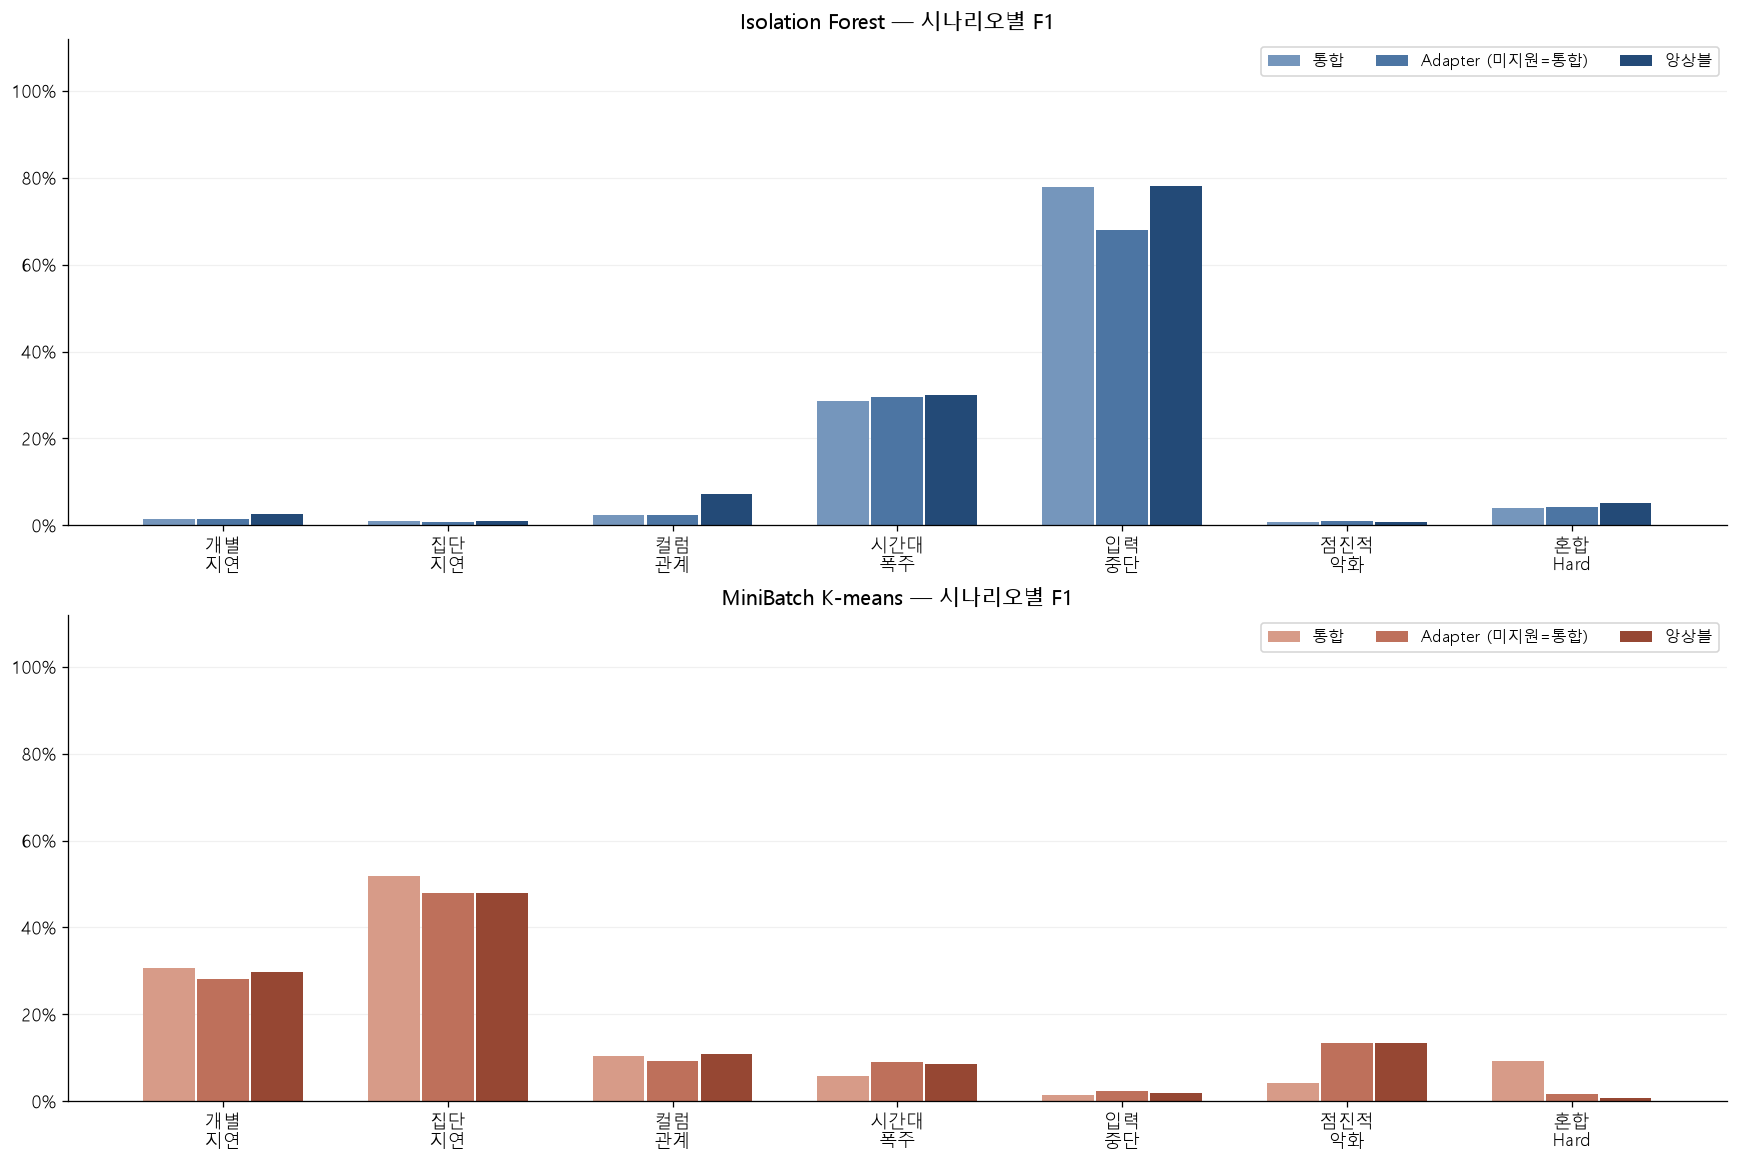

모델,기본 시나리오 수,Accuracy,Precision,Recall,F1
IF 통합,6,77.26%,27.87%,16.15%,18.64%
IF Adapter,6,78.15%,28.81%,13.97%,17.19%
IF 앙상블,6,76.18%,30.06%,18.28%,19.93%
K-means 통합,6,83.11%,26.51%,16.67%,17.43%
K-means Adapter,6,82.04%,25.20%,18.13%,18.30%
K-means 앙상블,6,82.84%,28.32%,18.04%,18.69%


In [8]:
show(plots.scenario_bars(summary, 'window'))
macro = pd.DataFrame(summary['macro_basic_scenarios']['window']).rename(columns={'method':'모델','accuracy':'Accuracy','precision':'Precision','recall':'Recall','f1':'F1','scenarios':'기본 시나리오 수'})
macro['모델'] = macro['모델'].map(plots.NAMES)
display(formatted(macro))

In [9]:
scenario_rows = []
for d in summary['datasets']:
    for r in d['window']['metrics']:
        scenario_rows.append({'시나리오':plots.SCENARIO_NAMES[d['dataset']], '모델':plots.NAMES[r['method']], '평가 수':r['n'], 'Accuracy':r['accuracy'], 'Precision':r['precision'], 'Recall':r['recall'], 'F1':r['f1'], '정상 오탐률':r['normal_false_positive_rate']})
display(formatted(pd.DataFrame(scenario_rows)))

시나리오,모델,평가 수,Accuracy,Precision,Recall,F1,정상 오탐률
개별 지연,IF 통합,"59,984",64.24%,0.95%,3.16%,1.46%,30.17%
개별 지연,IF Adapter,"59,984",64.95%,0.91%,2.96%,1.40%,29.38%
개별 지연,IF 앙상블,"59,984",62.16%,1.59%,5.79%,2.50%,32.69%
개별 지연,K-means 통합,"59,984",83.64%,23.84%,43.41%,30.78%,12.68%
개별 지연,K-means Adapter,"59,984",81.09%,20.59%,43.98%,28.05%,15.51%
개별 지연,K-means 앙상블,"59,984",82.52%,22.36%,43.94%,29.64%,13.96%
집단 지연,IF 통합,"363,830",84.25%,9.48%,0.48%,0.91%,0.82%
집단 지연,IF Adapter,"363,830",84.43%,10.06%,0.37%,0.71%,0.59%
집단 지연,IF 앙상블,"363,830",84.46%,13.06%,0.49%,0.94%,0.58%
집단 지연,K-means 통합,"363,830",88.12%,66.94%,42.45%,51.96%,3.74%


## 3. 혼동행렬: 틀린 이유가 무엇인가?

오른쪽 위는 정상인데 이상이라고 알린 **FP**, 왼쪽 아래는 이상인데 정상으로 놓친 **FN**이다. 왼쪽 위 TN과 오른쪽 아래 TP가 맞힌 결과다.

색은 실제 정상/이상 클래스 내부 비율이고 숫자는 실제 건수다. 정상 수가 많아 이상 누락이 색상에 가려지는 문제를 줄였다.

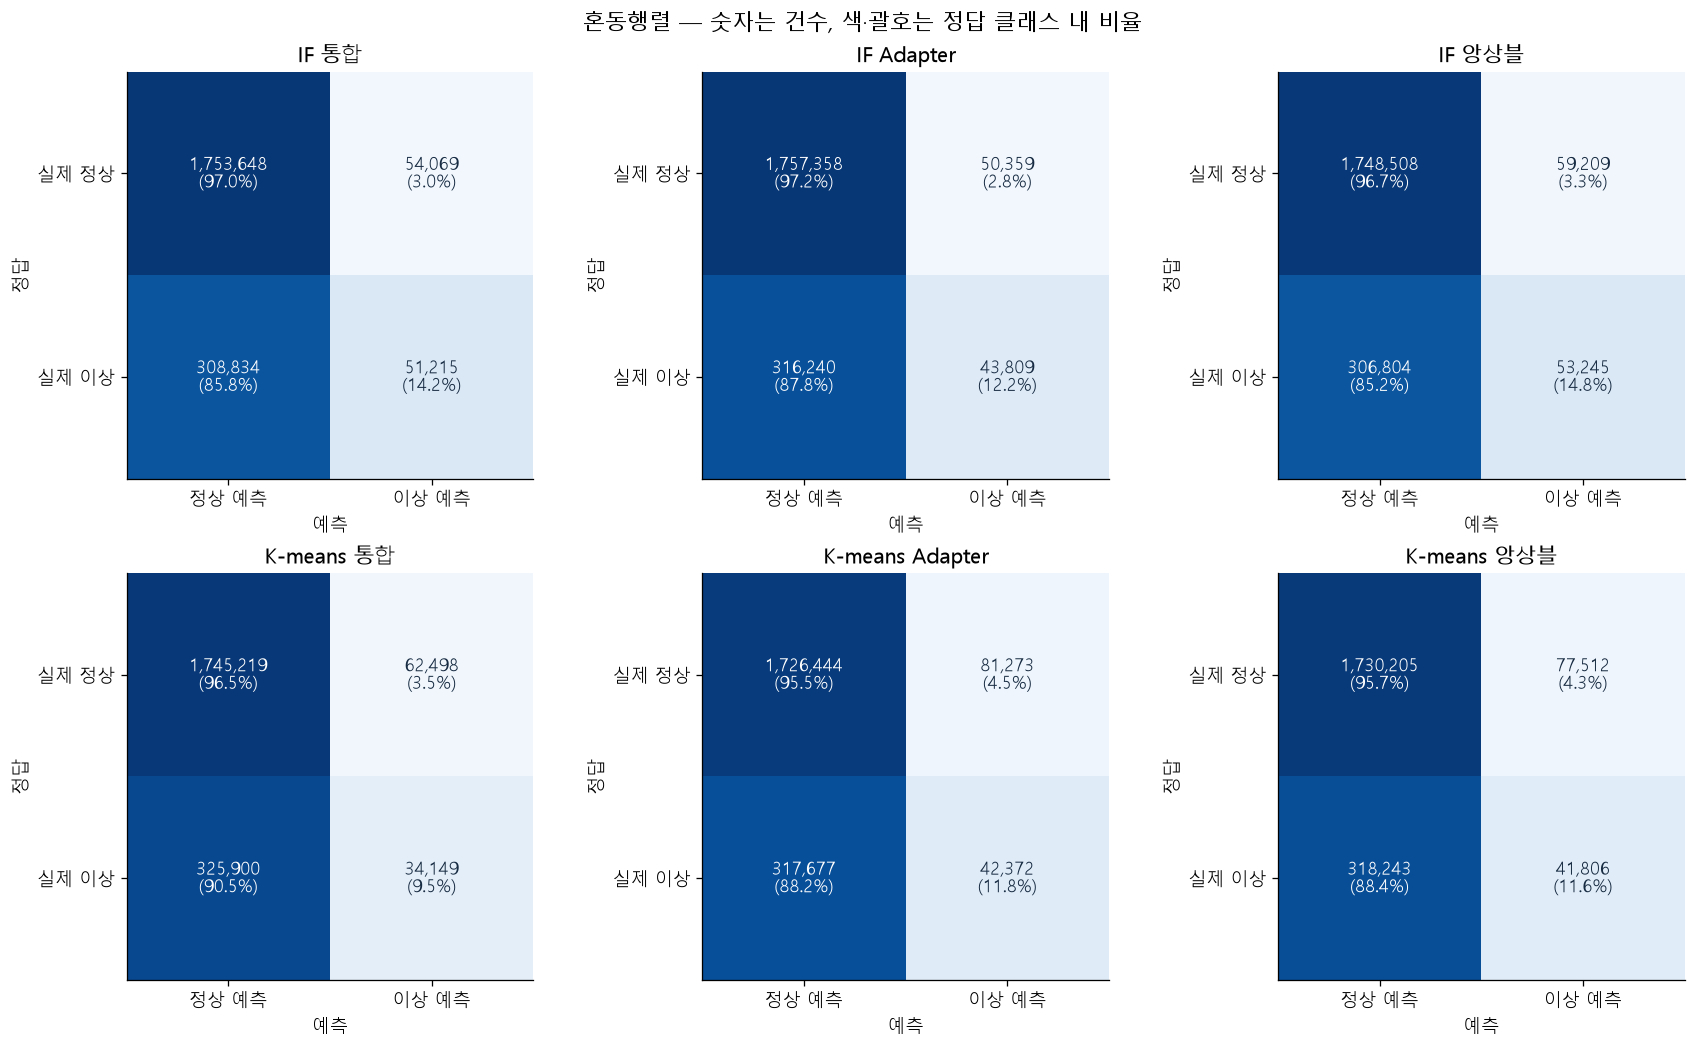

In [10]:
show(plots.confusion(summary, 'window'))

## 4. 점수 분포와 이상 탐지 판정선

IF 점수는 `-score_samples`, K-means 점수는 최근접 클러스터 중심까지의 거리다. 점수의 단위를 맞춘 뒤 경로별 임계값을 뺀 **margin**을 그린다.

- 점선 0보다 오른쪽: 모델이 이상 후보로 판정.
- 점선 왼쪽의 이상 정답: 놓친 이상.
- 점선 오른쪽의 정상 정답: 오경보.

같은 bins의 일반 히스토그램이다. 정상·이상 각 분포의 표시 영역 면적을 1로 맞췄으므로 막대 높이는 건수가 아니다. 그림만 전체 점수의 중앙 99% 근처를 표시하고, 표시 밖 비율을 각 패널에 적었다. **성능 계산은 잘라내지 않은 전체 데이터로 수행**했다. 분포가 정규분포를 닮는 것이 목표는 아니다.

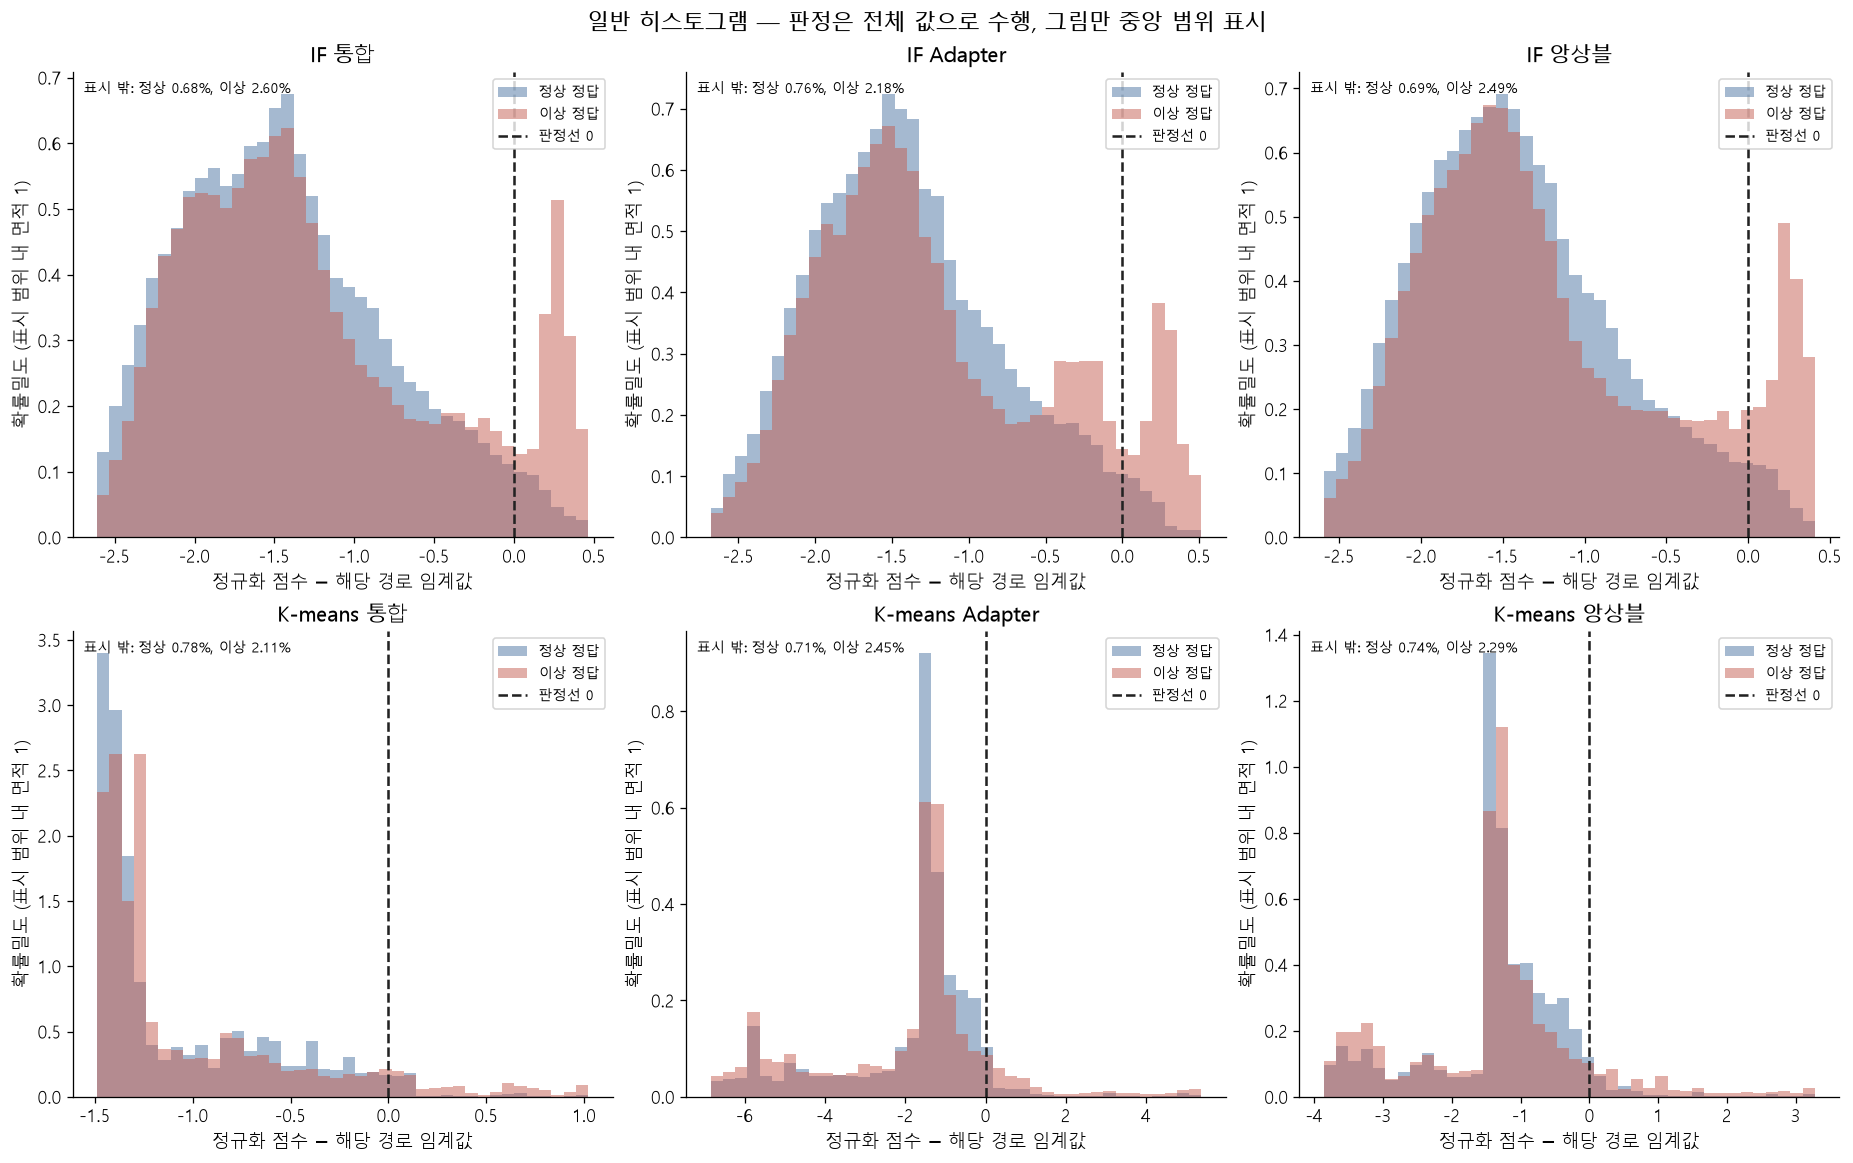

행별 점수 배열은 데이터 제외 정책으로 미포함. 저장된 전체 평가 분포 그림을 표시합니다.

In [11]:
if (RESULTS / 'input_stop/window_observed.npz').is_file():
    show(plots.margins(RESULTS, summary, 'window'))
else:
    display(Image(filename=str(RESULTS / 'figures/cell_19_00.png')))
    display(Markdown('행별 점수 배열은 데이터 제외 정책으로 미포함. 저장된 전체 평가 분포 그림을 표시합니다.'))

## 5. Adapter 모델은 어디에 실제로 적용됐나?

이상 점수가 아니라 정상 참조 데이터의 지원량으로 전용 모델 생성 여부를 정했다. 행 모델은 학습 500·정규화 검증 100·판정선 검증 100행과 학습 3일 이상이 필요하다. 시간창 모델은 각 분할의 **서로 다른 원본 실행 20개 이상**도 요구한다. 재생을 많이 했다는 이유만으로 원본 근거가 충분하다고 판단하지 않는다.

미지원 집단은 통합 모델로 fallback하므로 전체 결과만으로 ‘Adapter 전용 모델 자체’의 효과를 단정할 수 없다. 지원 집단만의 비교를 함께 제시한다.

In [12]:
support = pd.DataFrame(summary['protocol']['support'])
display(support[['unit','adapter','expert_available','train','calibration','threshold','train_days','reason']].style.format({'train':'{:,.0f}','calibration':'{:,.0f}','threshold':'{:,.0f}','train_days':'{:,.0f}'}, na_rep='N/A').hide(axis='index'))
coverage = pd.DataFrame([{'시나리오':plots.SCENARIO_NAMES[d['dataset']], '평가 수':d['window']['assessed'], 'fallback 수':d['window']['fallback'], 'fallback 비율':d['window']['fallback_rate']} for d in summary['datasets']])
display(coverage.style.format({'평가 수':'{:,.0f}','fallback 수':'{:,.0f}','fallback 비율':'{:.2%}'}).hide(axis='index'))
display(Markdown('**공통 Adapter 지원 시간창만의 성능:** 통합 모델도 같은 부분집합에서 재계산한 값이다.'))
display(formatted(plots.table(summary, 'window', supported=True)))

unit,adapter,expert_available,train,calibration,threshold,train_days,reason
row,DATA.DECRYPTOR,False,0,1,1,0,train<500; calibration<100; threshold<100; train_days<3
row,DATA.ENCRYPTOR,False,0,1,1,0,train<500; calibration<100; threshold<100; train_days<3
row,DATA.MAPPER,False,2,5,8,1,train<500; calibration<100; threshold<100; train_days<3
row,DATA.TRANSFORMER,False,8,15,21,3,train<500; calibration<100; threshold<100
row,DB.DELETER,False,1,0,1,1,train<500; calibration<100; threshold<100; train_days<3
row,DB.EXECUTOR,False,1,"1,022",979,1,train<500; train_days<3
row,DB.READER,True,"2,039",624,608,24,supported
row,DB.UPDATER,False,8,17,18,4,train<500; calibration<100; threshold<100
row,DB.WRITER,True,"2,051",615,598,24,supported
row,FILE.EXECUTOR,False,0,3,5,0,train<500; calibration<100; threshold<100; train_days<3


시나리오,평가 수,fallback 수,fallback 비율
개별 지연,"59,984","22,500",37.51%
집단 지연,"363,830","136,342",37.47%
컬럼 관계,"60,000",0,0.00%
시간대 폭주,"398,856","303,808",76.17%
입력 중단,"502,488","382,936",76.21%
점진적 악화,"602,814","226,112",37.51%
혼합 Hard,"179,794",0,0.00%


**공통 Adapter 지원 시간창만의 성능:** 통합 모델도 같은 부분집합에서 재계산한 값이다.

모델,평가 수,정상 수,이상 수,Accuracy,Precision,Recall,F1,정상 오탐률,모두 정상 예측 Accuracy
IF 통합,"1,096,068","888,557","207,511",79.03%,28.35%,7.05%,11.29%,4.16%,81.07%
IF Adapter,"1,096,068","888,557","207,511",78.69%,17.84%,3.48%,5.82%,3.74%,81.07%
IF 앙상블,"1,096,068","888,557","207,511",78.75%,28.34%,8.03%,12.51%,4.74%,81.07%
K-means 통합,"1,096,068","888,557","207,511",79.52%,33.12%,8.04%,12.93%,3.79%,81.07%
K-means Adapter,"1,096,068","888,557","207,511",78.55%,32.19%,12.00%,17.48%,5.90%,81.07%
K-means 앙상블,"1,096,068","888,557","207,511",78.85%,33.32%,11.73%,17.35%,5.48%,81.07%


## 6. 개별 Process 행 기준의 6개 비교

이 부분은 기존 행 피처 체계의 한계를 확인하는 비교다. 개별 지연·집단 지연·컬럼 관계 이상과 Hard의 point 이상을 평가한다. collective-only 행은 정상 정답으로 잘못 넣지 않고 제외한다.

**폭주·중단·누적 악화는 행 분류 성능 N/A**다. 특히 중단 사건은 행 자체가 없으므로 행 IF/K-means가 직접 점수를 낼 수 없다. 시간창 결과와 행 결과는 다른 모델 입력과 다른 분모이므로 성능을 합치거나 직접 순위를 매기지 않는다.

모델,평가 수,정상 수,이상 수,Accuracy,Precision,Recall,F1,정상 오탐률,모두 정상 예측 Accuracy
IF 통합,"1,701,995","1,601,311","100,684",93.56%,0.00%,0.00%,0.00%,0.55%,94.08%
IF Adapter,"1,701,995","1,601,311","100,684",91.39%,0.76%,0.35%,0.48%,2.89%,94.08%
IF 앙상블,"1,701,995","1,601,311","100,684",90.90%,0.48%,0.26%,0.34%,3.40%,94.08%
K-means 통합,"1,701,995","1,601,311","100,684",94.04%,13.83%,0.14%,0.27%,0.05%,94.08%
K-means Adapter,"1,701,995","1,601,311","100,684",93.62%,35.71%,9.83%,15.41%,1.11%,94.08%
K-means 앙상블,"1,701,995","1,601,311","100,684",92.92%,18.99%,6.01%,9.13%,1.61%,94.08%


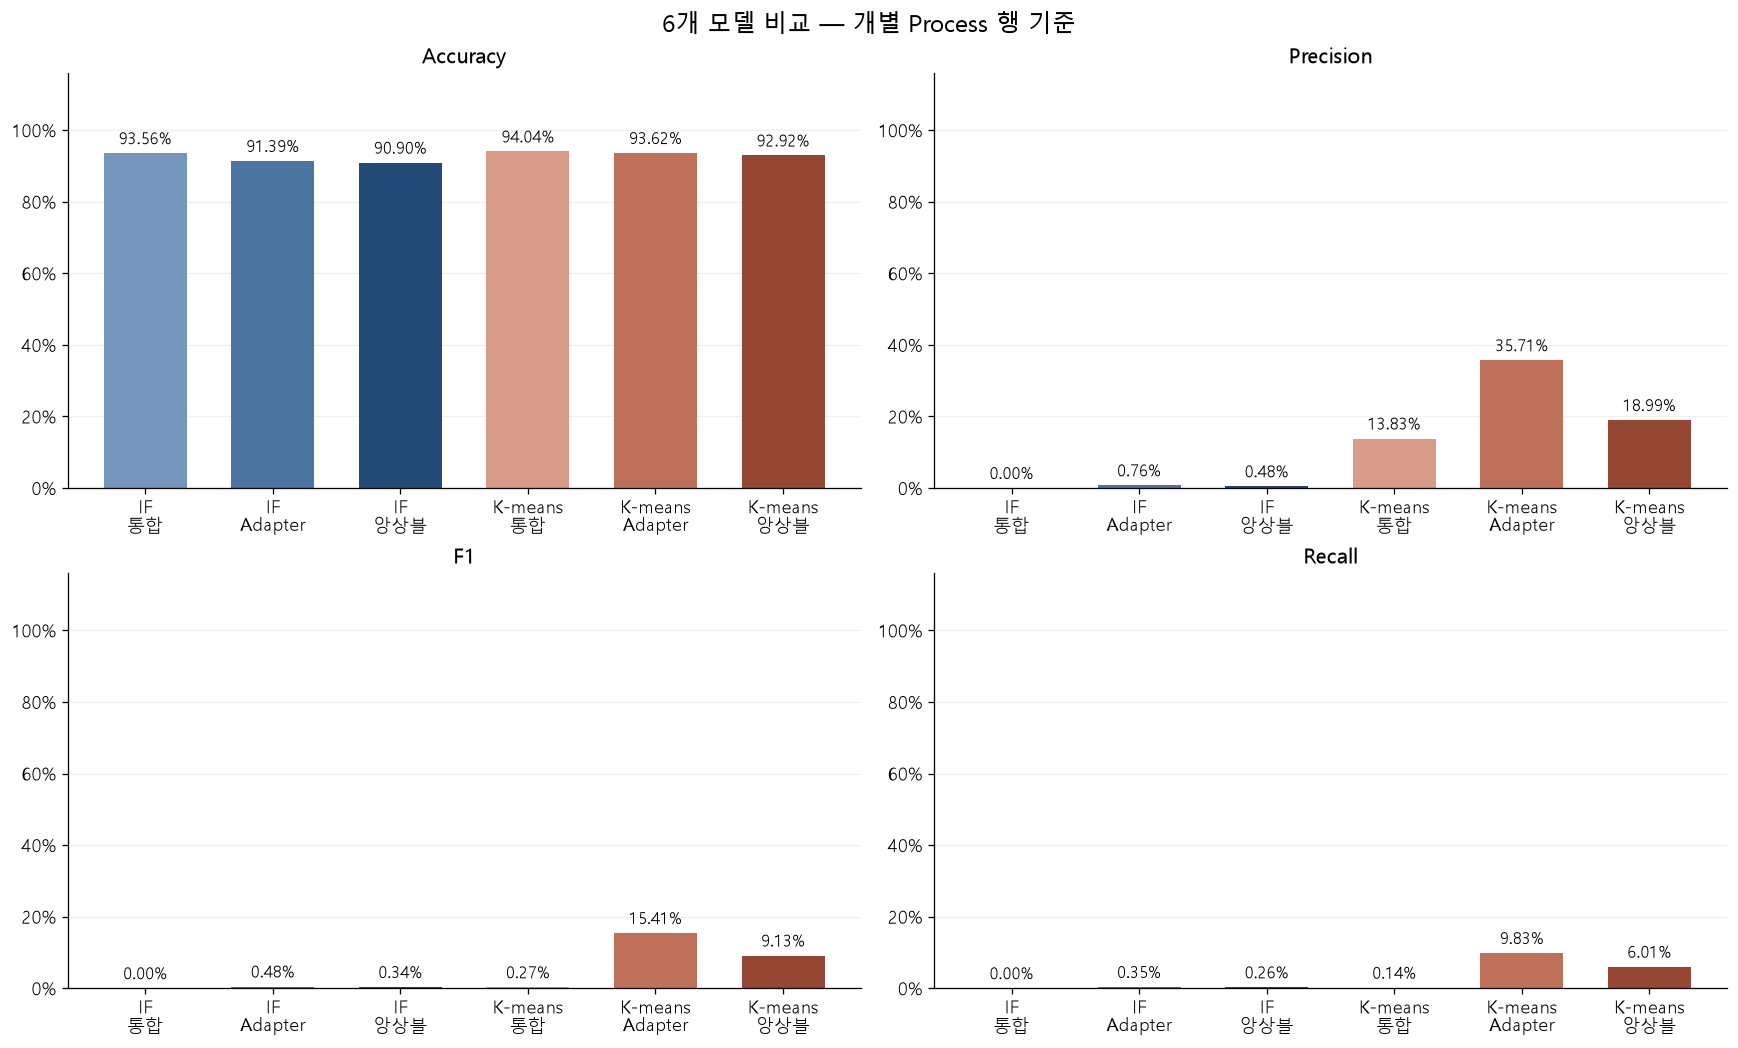

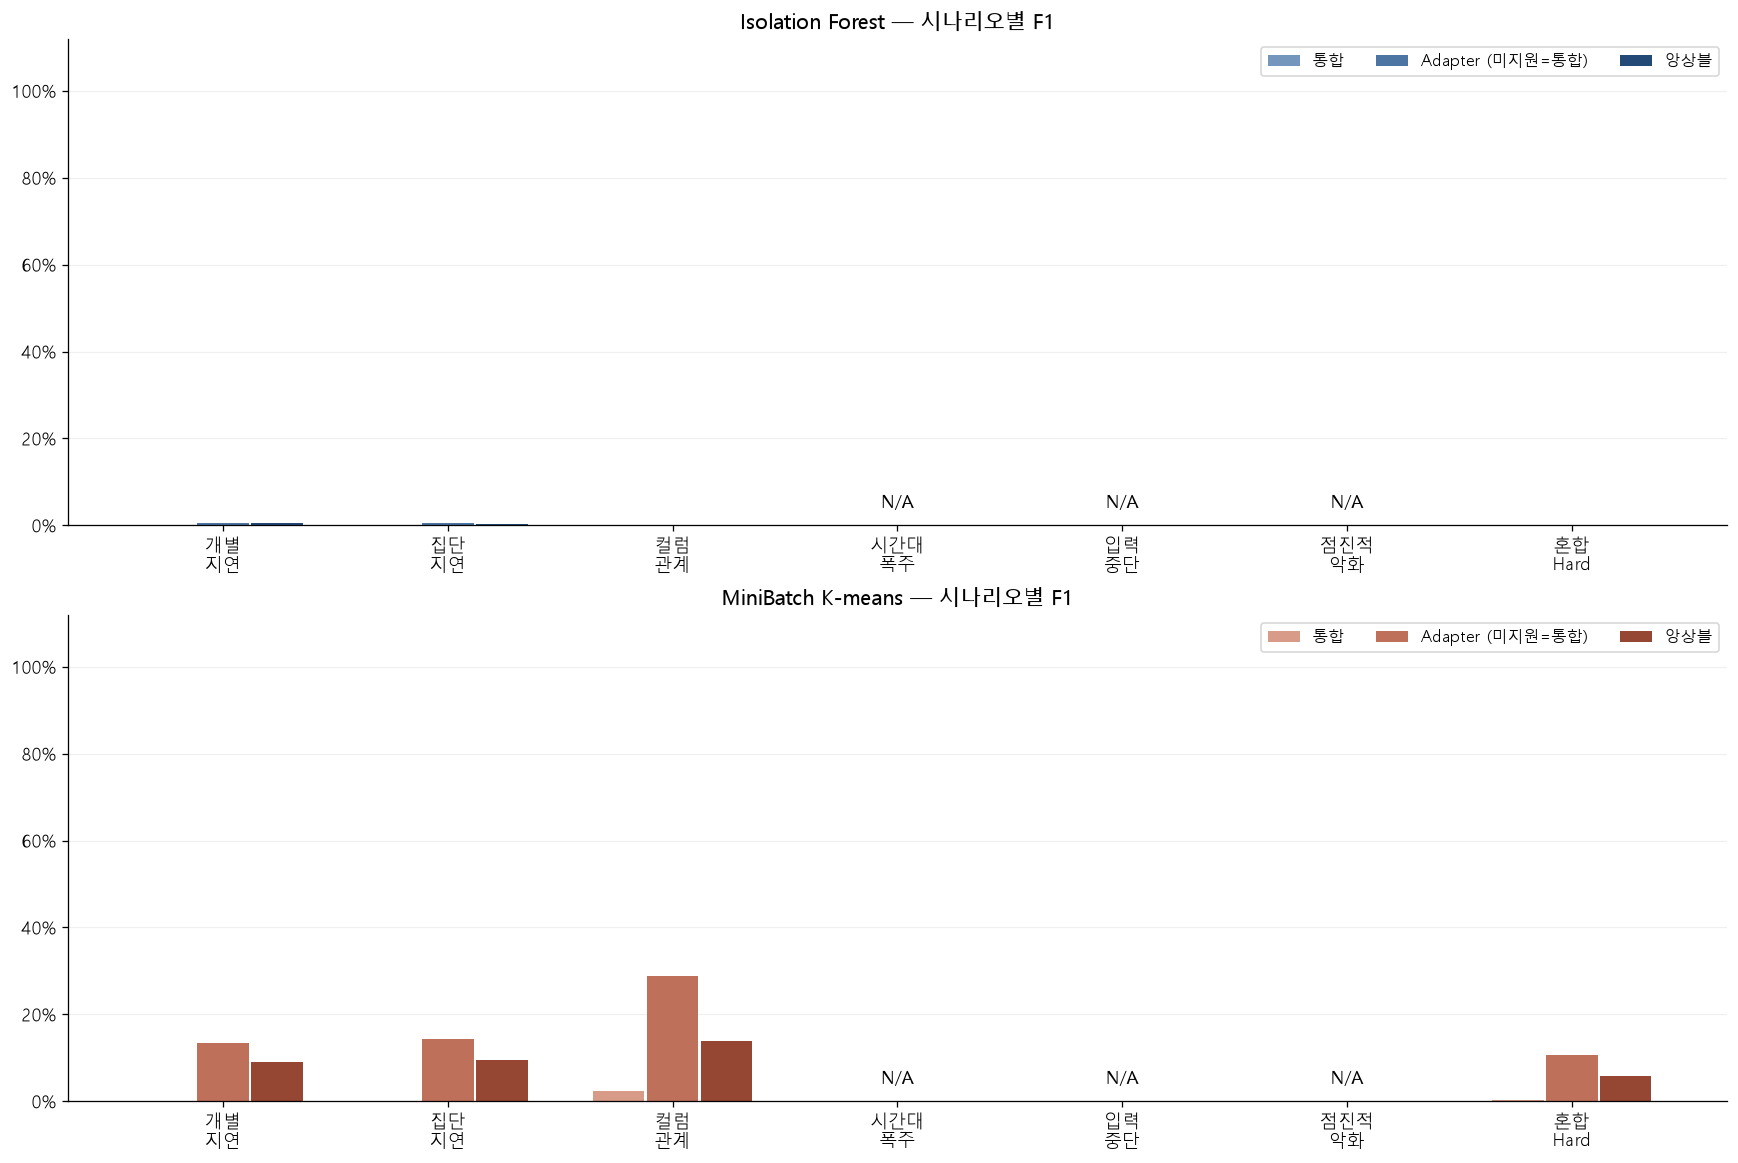

In [13]:
display(formatted(plots.table(summary, 'row')))
show(plots.overview(summary, 'row'))
show(plots.scenario_bars(summary, 'row'))

## 7. 혼합 Hard는 6개 사건을 모두 찾았나?

한 사례에 6개 유형이 동시에 존재한다. 하나만 찾았다고 전체를 성공으로 처리하지 않는다. 위쪽은 유형별 사건 탐지율이고, 아래쪽은 **6개를 전부 찾은 사례 비율**이다.

사건 탐지는 정답 구간과 겹치는 감시 시간창에서 경보가 있었는지로 평가한다. 이 사건 판정을 분/행의 정답으로 되돌려 F1을 부풀리는 point adjustment는 하지 않는다.

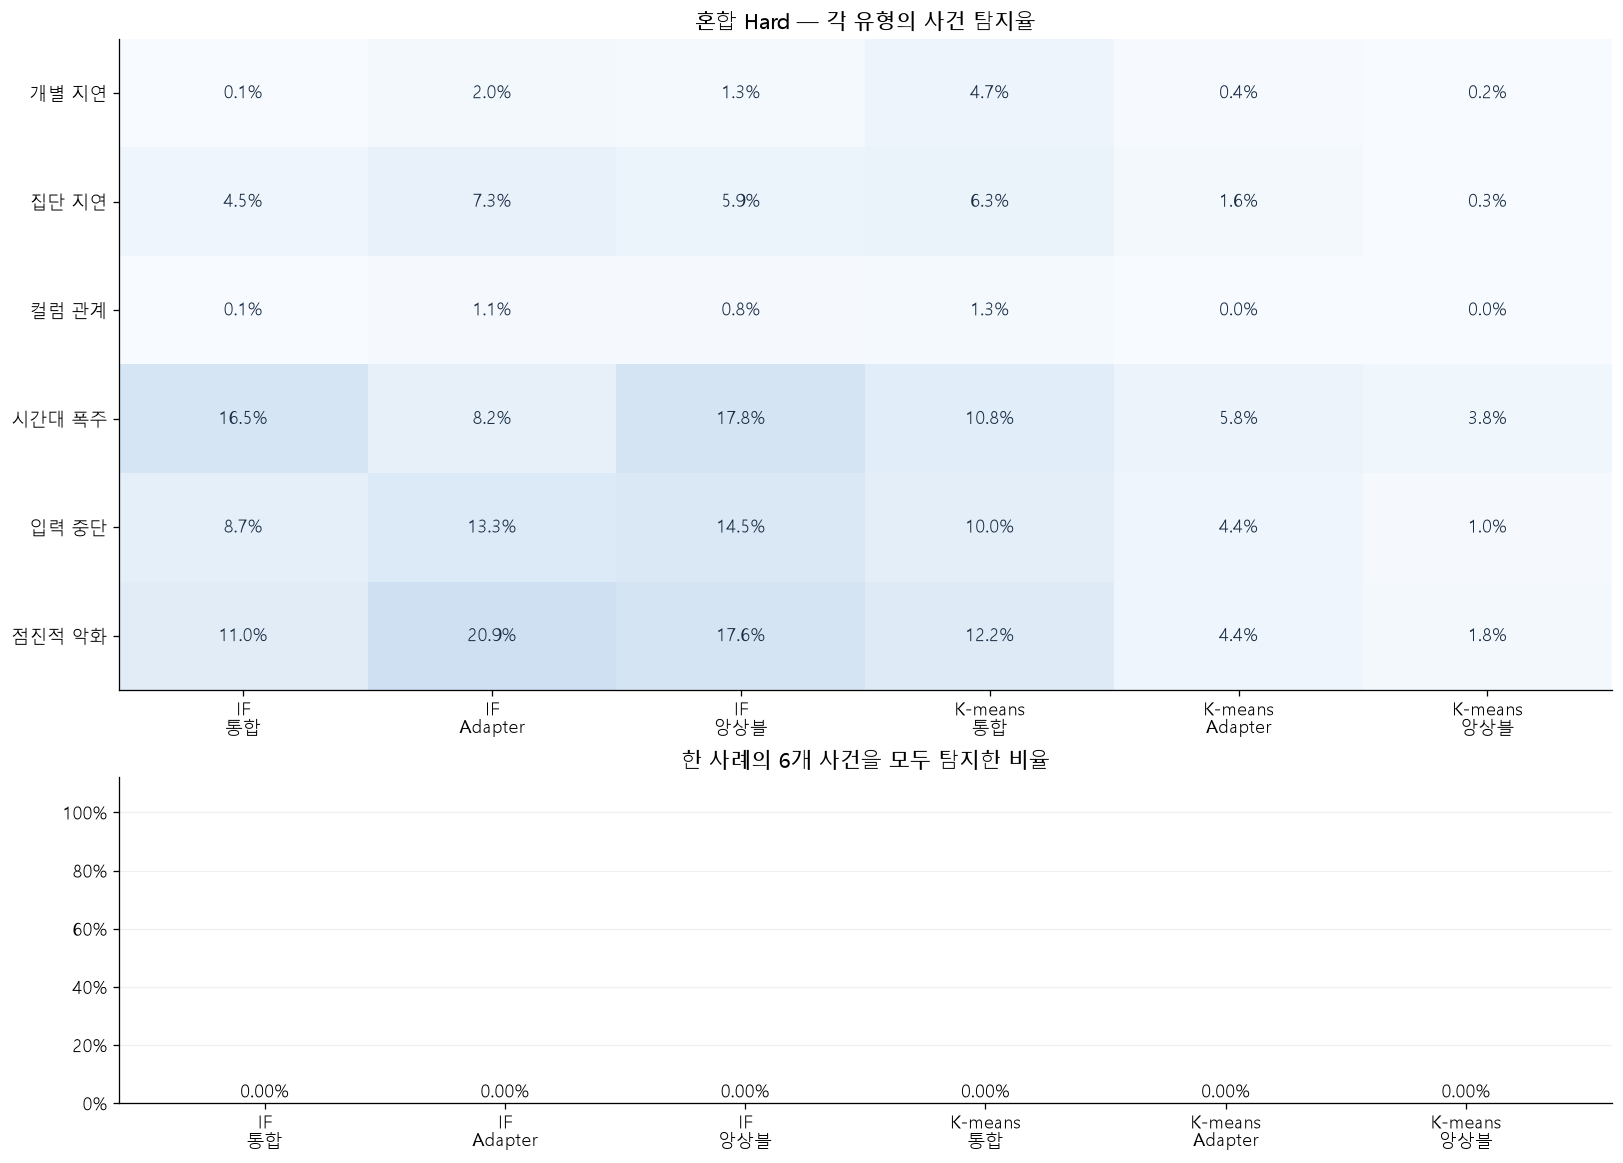

평가셋,사건 유형,모델,사건 수,탐지 수,사건 탐지율,최초 탐지 지연 중앙값(초)
개별 지연,개별 지연,IF 통합,"5,000",159,3.18%,60.0
개별 지연,개별 지연,IF Adapter,"5,000",143,2.86%,60.0
개별 지연,개별 지연,IF 앙상블,"5,000",291,5.82%,60.0
개별 지연,개별 지연,K-means 통합,"5,000","2,182",43.64%,60.0
개별 지연,개별 지연,K-means Adapter,"5,000","2,211",44.22%,60.0
개별 지연,개별 지연,K-means 앙상블,"5,000","2,209",44.18%,60.0
집단 지연,집단 지연,IF 통합,"5,000",189,3.78%,300.0
집단 지연,집단 지연,IF Adapter,"5,000",142,2.84%,270.0
집단 지연,집단 지연,IF 앙상블,"5,000",180,3.60%,300.0
집단 지연,집단 지연,K-means 통합,"5,000","2,235",44.70%,60.0


In [14]:
show(plots.hard_results(summary))
event_rows = []
for d in summary['datasets']:
    for r in d['window']['events']['per_type']:
        event_rows.append({'평가셋':plots.SCENARIO_NAMES[d['dataset']], '사건 유형':plots.SCENARIO_NAMES[r['scenario']], '모델':plots.NAMES[r['method']], '사건 수':r['events'], '탐지 수':r['detected'], '사건 탐지율':r['event_recall'], '최초 탐지 지연 중앙값(초)':r['median_delay_seconds']})
display(pd.DataFrame(event_rows).style.format({'사건 수':'{:,.0f}','탐지 수':'{:,.0f}','사건 탐지율':'{:.2%}','최초 탐지 지연 중앙값(초)':'{:.1f}'}, na_rep='미탐지').hide(axis='index'))

## 8. 정상 사례 전체에서 경보가 한 번이라도 발생했나?

분당 오탐률이 낮아도 50~90분 에피소드에서는 경보가 한 번 이상 발생할 가능성이 커진다. 아래 표는 정상 대조 사례에서 경보가 발생한 사례 비율이다. 원래 기간·표본 양성 비율에 영향을 받는 Precision과 구분해서 읽는다.

In [15]:
case_fpr = pd.DataFrame([{'시나리오':plots.SCENARIO_NAMES[d['dataset']], **{plots.NAMES[m]:d['window']['events']['normal_case_false_alarm_rate'][m] for m in METHODS}} for d in summary['datasets']])
display(case_fpr.style.format({plots.NAMES[m]:'{:.2%}' for m in METHODS}).hide(axis='index'))

시나리오,IF 통합,IF Adapter,IF 앙상블,K-means 통합,K-means Adapter,K-means 앙상블
개별 지연,71.34%,70.18%,75.46%,2.26%,9.54%,5.38%
집단 지연,13.50%,12.26%,12.10%,2.66%,6.26%,5.54%
컬럼 관계,73.16%,76.18%,81.98%,13.20%,10.26%,3.14%
시간대 폭주,19.52%,20.10%,20.34%,3.10%,4.94%,3.92%
입력 중단,16.24%,16.86%,16.40%,3.20%,4.60%,4.16%
점진적 악화,17.86%,17.52%,16.42%,2.76%,6.60%,5.78%
혼합 Hard,34.70%,56.30%,49.10%,15.30%,15.40%,7.50%


## 9. 입력 중단 실제 사례 읽기

case_id 정렬상 첫 사례를 고정해서 보여준다. 잘 탐지된 사례만 골라 보여준 그림이 아니다. 파란색은 장애를 주입하지 않은 정상 대조군, 빨간색은 입력을 제거한 관측 입력이다. 음영은 정답 이상 구간이다.

시간축의 0은 첫 시간창의 완료 시각이다. 이 첫 사례는 DATA.ENCRYPTOR이며 전용 모델의 원본 학습 지원이 부족하다. Adapter·앙상블 전략도 통합 모델로 fallback하므로 같은 알고리즘의 세 곡선이 동일하다.

입력 수가 0이 되더라도 정상적인 짧은 공백과 겹칠 수 있다. 5분 문맥이 충분히 낮아지기 전에는 놓치거나 지연 탐지할 수 있다. 완료 로그가 없으면 시간 P95는 결측으로 남기며 0ms로 조작하지 않는다. 각 모델의 margin이 0을 넘는 구간이 경보다.

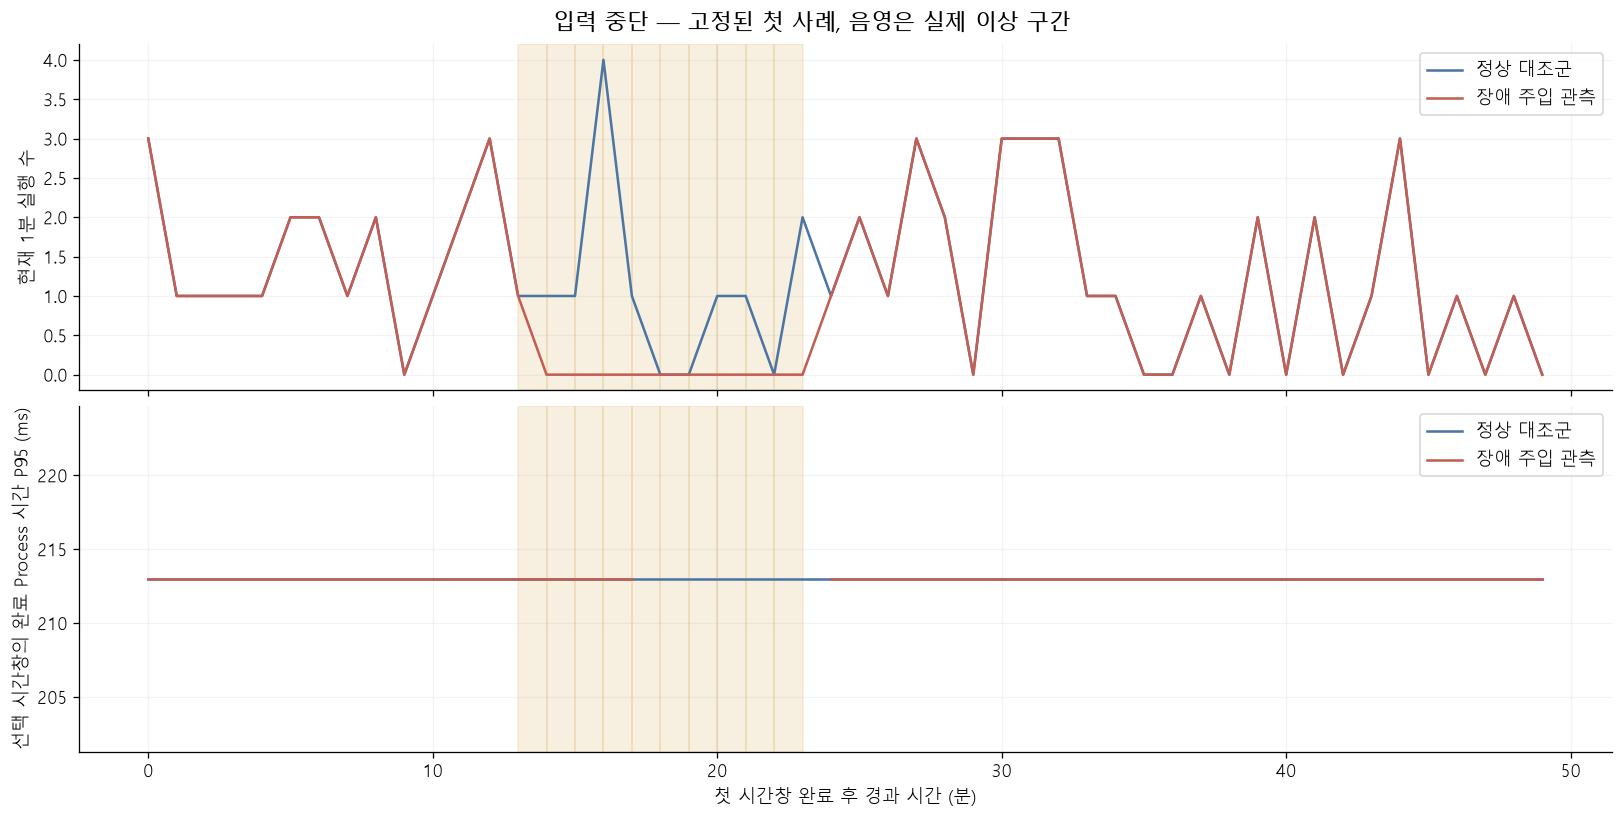

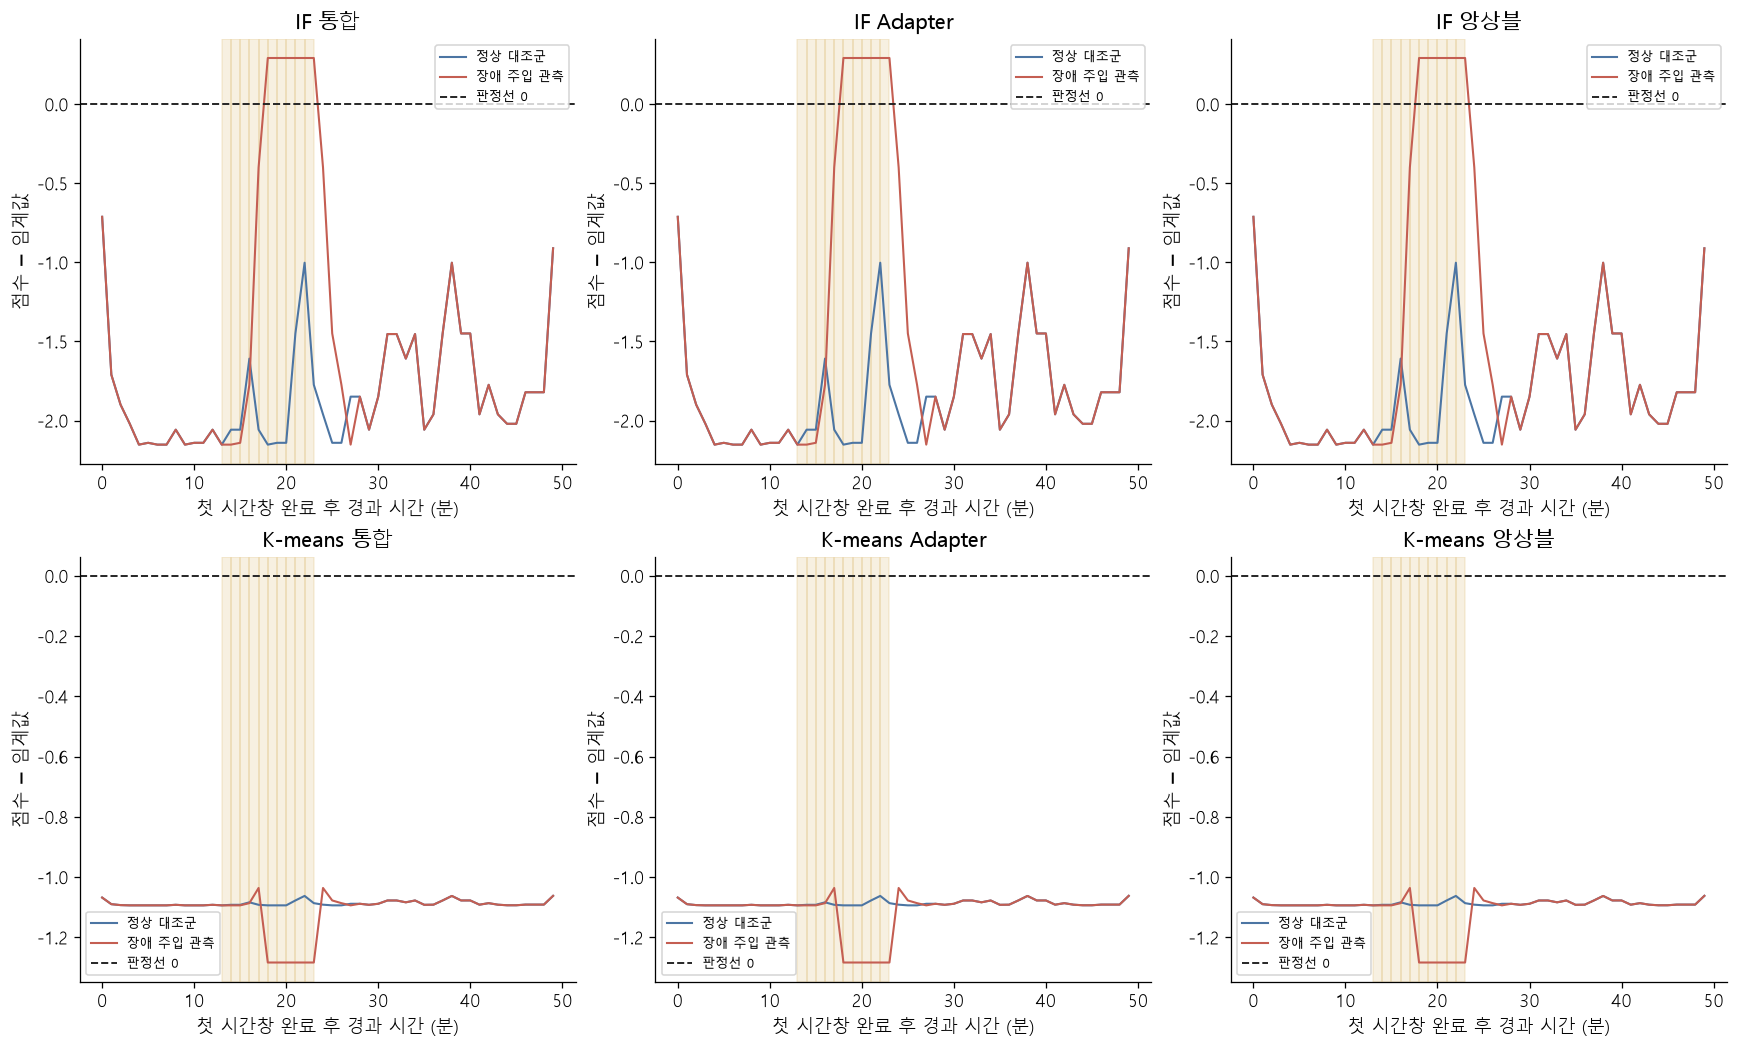

재생 입력은 미포함. 고정된 첫 사례의 저장된 타임라인을 표시합니다.

In [16]:
if (RESULTS / 'input_stop/window_observed.npz').is_file():
    raw_fig, score_fig = plots.timeline(RESULTS, summary, 'input_stop', case_index=0)
    raw_fig.axes[-1].set_xlabel('첫 시간창 완료 후 경과 시간 (분)')
    for ax in score_fig.axes:
        ax.set_xlabel('첫 시간창 완료 후 경과 시간 (분)')
    show(raw_fig)
    show(score_fig)
else:
    display(Image(filename=str(RESULTS / 'figures/cell_29_00.png')))
    display(Image(filename=str(RESULTS / 'figures/cell_29_01.png')))
    display(Markdown('재생 입력은 미포함. 고정된 첫 사례의 저장된 타임라인을 표시합니다.'))

## 10. 학습 데이터·피처·하이퍼파라미터

행 모델은 기존 정상 원본의 시간 분할을 유지한다. 시간창 모델은 원본 template ID 고정 해시로 약 25%를 검증용 예약하고, 이 실행을 학습·calibration·threshold와 평소 소요시간 기준에서 제외했다. calibration과 threshold는 서로 다른 실행이다. 새 검증 사례는 예약 실행만으로 생성한다. 가상 날짜는 겹칠 수 있어 실제 미래 시계열 holdout은 아니다.

시간창 길이만 후보 탐색을 했다. K=6·IF 128 trees·P99·50:50은 고정한 초기 설정이다. 최종 테스트 결과로 이 설정이나 시간창을 다시 조정하지 않았다. 최근 W분 처리시간 분위수는 실제 완료 Process 값에서 재계산한다. 별도 5분 요청량에 겹치는 W분 요청량을 다시 더하지 않는다.

In [17]:
display(pd.DataFrame(summary['protocol']['row_reference']))
display(pd.DataFrame(summary['protocol']['window_reference']))
display(pd.DataFrame(list(summary['protocol']['identity']['config'].items()), columns=['설정','값']))
for unit, features in summary['protocol']['features'].items():
    display(Markdown(f'**{unit} 피처**: ' + ', '.join(features)))
display(pd.DataFrame([summary['protocol']['versions']]))

,split,rows,workflows,first,last
0,train,10023,5951,2025-12-24T13:28:35.077000,2026-03-23T10:06:02.739000
1,calibration,3312,2621,2026-03-24T10:17:52.698000,2026-08-19T23:48:15.036000
2,threshold,3215,2522,2026-03-24T14:32:15.174000,2026-08-19T23:49:00.045000


,split,normal_episodes,windows,independent_source_templates,adapters
0,train,120,10825,4448,15
1,calibration,144,12987,1952,18
2,threshold,128,11572,1917,16


,설정,값
0,seed,42.00
1,quantile,0.99
2,global_weight,0.50
3,n_estimators,128.00
4,max_samples,512.00
5,k,6.00
6,kmeans_batch_size,2048.00
7,kmeans_n_init,5.00
8,kmeans_max_iter,100.00
9,min_train,500.00


**row 피처**: log_duration_ms, missing_duration_ms, log_totalCount, missing_totalCount, log_retryCount, missing_retryCount, hour_sin, hour_cos, weekday_sin, weekday_cos

**window 피처**: log_arrivals, arrival_deviation, log_arrivals_5m, arrival_deviation_5m, log_p50_duration, log_p95_duration, p95_duration_relative, missing_duration, hour_sin, hour_cos, weekday_sin, weekday_cos

,python,sklearn,numpy,pandas
0,3.12.14,1.9.1,2.5.3,3.0.6


### 실제 판정선과 근거

IF raw 점수는 비정상일수록 커지도록 부호를 바꿨다. K-means raw 점수는 표준화 피처 공간의 최근접 중심 거리다. calibration 중앙값을 빼고 P95-중앙값으로 나눈 점수를 사용한다.

raw/normalized threshold는 각 모델의 정상 threshold 집단 P99이고, ensemble threshold는 해당 경로에서 두 점수를 합친 정상 점수 P99다. Adapter 경로가 없으면 GLOBAL 값과 점수를 사용한다. 그림에서 0은 **점수−이 임계값**의 기준이지 raw threshold가 전부 0이라는 뜻이 아니다.

이 모델 점수 P99는 기존 하드룰의 ‘소요시간·건수 P99’와 다른 기준이다. 평가셋은 기존 하드룰을 통과했지만 모델 점수는 판정선을 넘을 수 있다.

In [18]:
thresholds = pd.DataFrame(summary['protocol']['thresholds'])
display(thresholds.style.format({'raw_threshold':'{:.5f}','normalized_threshold':'{:.5f}','ensemble_threshold':'{:.5f}','normalizer_median':'{:.5f}','normalizer_spread':'{:.5f}','effective_k':'{:,.0f}'},na_rep='N/A').hide(axis='index'))

unit,algorithm,route,raw_threshold,normalized_threshold,ensemble_threshold,normalizer_median,normalizer_spread,effective_k
row,if,GLOBAL,0.69567,1.27016,1.27016,0.63936,0.04433,N/A
row,if,DB.READER,0.70259,1.37695,0.89405,0.65743,0.03279,N/A
row,if,DB.WRITER,0.71730,2.55228,1.27169,0.65840,0.02308,N/A
row,if,SERVICE.EXECUTOR,0.77730,1.08197,1.17050,0.73281,0.04111,N/A
row,kmeans,GLOBAL,2.05177,1.30492,1.30492,1.47992,0.43823,6
row,kmeans,DB.READER,2.97958,1.50738,0.93385,1.79365,0.78675,6
row,kmeans,DB.WRITER,3.06567,1.05513,0.65562,2.66690,0.37794,6
row,kmeans,SERVICE.EXECUTOR,13.86558,1.00676,1.18838,7.10177,6.71842,6
window,if,GLOBAL,0.64874,1.51001,1.51001,0.52335,0.08303,N/A
window,if,DB.READER,0.70447,1.46108,1.39364,0.55148,0.10471,N/A


## 11. 이 결과로 말할 수 있는 것과 없는 것

- 모델·전략별로 어떤 주입 시나리오를 찾고 놓치는지, 정상 대조군에 얼마나 경보를 내는지 비교할 수 있다.
- 이 데이터는 반합성 스트레스 테스트이며 정상 원본 패턴을 학습과 생성에 재사용한다. 실제 장애 정확도나 독립 외부 데이터 성능의 증거가 아니다.
- TARGET 시간창은 사전에 감시할 업무 집단을 정했다는 가정이다. 실제 서비스에서는 모든 업무 집단을 감시해야 하며 정답을 보고 대상 집단을 선택하면 안 된다.
- 시간창은 오프라인 event-time 기준이다. 실제 입력이 완료 로그뿐이면 요청 수·중단을 제때 계산하기 위한 도착 이벤트 또는 watermark·지연 도착 정책이 필요하다.
- 점수 차이는 확률·원인 기여도·장애 확정 여부가 아니다. 거리와 고립 정도가 정상 참조 범위를 벗어났다는 근거다.
- 반복 학습 seed 실험, 실제 정상 장기 운영 오경보, 독립 장애 평가, backend 연동은 이번 실험의 범위 밖이다.

### 이번 재학습 결과의 결론

검증에서 선택한 공통 5분 시간창으로 재학습한 결과, 최고 F1은 IF 앙상블의 22.54%였다. 동일한 새 학습 참조의 고정 1분 대조 모델은 6.22%였다. Recall은 3.33%에서 14.79%로 늘었지만 정상 오탐률도 0.70%에서 3.28%로 늘었다. 입력 중단 탐지는 개선되었으나 Hard의 6개 사건을 모두 찾은 사례는 여전히 0%다. 따라서 이번 후보 탐색에서 개선은 확인되었지만 운영 채택을 위한 충분한 성능이나 보편적 최적 시간창을 입증한 것은 아니다.

### 참고 자료

- [scikit-learn IsolationForest](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.IsolationForest.html)
- [scikit-learn MiniBatchKMeans](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.MiniBatchKMeans.html)
- [분류 평가 지표 정의](https://scikit-learn.org/stable/modules/model_evaluation.html)

자세한 실행 방법과 프로토콜은 같은 폴더의 `README.md`, 실제 결과·재현성 해시는 `reports/model_evaluation_v2/summary.json`과 `protocol.json`에 있다.